# Fast Swing% — Pull Air% Analysis
Tests Fast Swing% (bat speed above fixed threshold) as a predictor of
Pull Air% and Pull% (Air Only), alongside swing shape metrics.

**Thresholds tested:** 73, 74, 75 mph  
**Denominators:** all tracked swings / contact events only  
**Model:** OLS with scaled predictors (standardised coefficients + p-values)


## 1. Imports & Config

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import spearmanr, pearsonr
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

pd.set_option("display.float_format", "{:.4f}".format)

FAST_THRESHOLDS = [73, 74, 75]   # mph
MIN_SWINGS      = 25             # minimum tracked swings to qualify
MIN_BBE         = 20             # minimum batted balls for pull air metrics

PITCH_BUCKETS = {
    "fastball": {"FF", "FA", "SI", "FT", "FC"},
    "breaking": {"SL", "ST", "SV", "CU", "KC", "CS"},
    "offspeed": {"CH", "FS", "FO", "EP", "KN"},
}

def bucket_pitch(pt):
    for bucket, types in PITCH_BUCKETS.items():
        if pt in types:
            return bucket
    return None

print("Imports OK")


Imports OK


## 2. Load Data

In [2]:
raw_2024 = pd.read_parquet(Path("statcast_2024.parquet"))
raw_2025 = pd.read_parquet(Path("statcast_2025.parquet"))
raw_all  = pd.concat([raw_2024, raw_2025], ignore_index=True)

print(f"Combined rows: {len(raw_all):,}")

# ── All tracked swings (bat_speed present)
swings = raw_all[
    raw_all["bat_speed"].notna() &
    raw_all["stand"].notna() &
    raw_all["batter"].notna()
].copy().reset_index(drop=True)

# ── Contact events only
contact = raw_all[
    raw_all["bat_speed"].notna() &
    raw_all["launch_speed"].notna() &
    raw_all["launch_angle"].notna() &
    raw_all["hc_x"].notna() &
    raw_all["hc_y"].notna() &
    raw_all["stand"].notna() &
    raw_all["batter"].notna()
].copy().reset_index(drop=True)

# ── Spray angle on contact
for df in [contact]:
    df["spray_angle_norm"] = np.where(
        df["stand"] == "R",
        np.degrees(np.arctan((df["hc_x"] - 125.42) / (198.27 - df["hc_y"]))),
        -np.degrees(np.arctan((df["hc_x"] - 125.42) / (198.27 - df["hc_y"]))),
    )
    df["pull_flag"]      = (df["spray_angle_norm"] > 0).astype(int)
    df["air_ball"]       = (df["launch_angle"] >= 10).astype(int)
    df["pull_air"]       = (
        (df["spray_angle_norm"] > 0) & (df["launch_angle"] >= 10)
    ).astype(int)
    df["pull_given_air"] = np.where(df["air_ball"] == 1, df["pull_flag"], np.nan)
    df["pitch_bucket"]   = df["pitch_type"].map(bucket_pitch)

# ── Attack direction normalised
for df in [swings, contact]:
    if "attack_direction" in df.columns:
        df["attack_direction_norm"] = np.where(
            df["stand"] == "R",
            df["attack_direction"],
            -df["attack_direction"],
        )

print(f"Tracked swings  : {len(swings):,}  ({swings['batter'].nunique()} batters)")
print(f"Contact events  : {len(contact):,}  ({contact['batter'].nunique()} batters)")
print(f"\nbat_speed distribution (swings):")
print(swings["bat_speed"].describe().round(2))


Combined rows: 1,466,750
Tracked swings  : 647,514  (898 batters)
Contact events  : 231,859  (851 batters)

bat_speed distribution (swings):
count   647514.0000
mean        69.5600
std          9.0700
min          0.6000
25%         67.1000
50%         71.1000
75%         74.4000
max         88.0000
Name: bat_speed, dtype: Float64


## 3. Compute Fast Swing% — Both Denominators

In [3]:
def fast_swing_pct(df, threshold, min_n, label):
    """
    Compute per-batter Fast Swing% = swings >= threshold / total swings.
    df must have bat_speed and batter columns.
    label used as column suffix.
    """
    agg = (
        df.groupby("batter")
        .agg(
            n_swings   = ("bat_speed", "count"),
            n_fast     = ("bat_speed", lambda x: (x >= threshold).sum()),
            mean_bs    = ("bat_speed", "mean"),
        )
        .query(f"n_swings >= {min_n}")
        .reset_index()
    )
    agg[f"fast_pct_{label}_{threshold}"] = agg["n_fast"] / agg["n_swings"]
    return agg[["batter", f"fast_pct_{label}_{threshold}", "mean_bs",
                "n_swings"]].rename(columns={"mean_bs": f"mean_bs_{label}"})

# All tracked swings
fs_swings = {}
for t in FAST_THRESHOLDS:
    fs_swings[t] = fast_swing_pct(swings, t, MIN_SWINGS, "all")

# Contact only
fs_contact = {}
for t in FAST_THRESHOLDS:
    fs_contact[t] = fast_swing_pct(contact, t, MIN_BBE, "contact")

# Print threshold sensitivity
print("Fast Swing% distribution by threshold:")
print(f"{'Threshold':>12}  {'Denom':>10}  {'mean':>8}  {'std':>8}  "
      f"{'n batters':>10}")
print("-" * 55)
for t in FAST_THRESHOLDS:
    for label, fs_dict in [("all swings", fs_swings), ("contact", fs_contact)]:
        col = f"fast_pct_{'all' if label == 'all swings' else 'contact'}_{t}"
        d   = fs_dict[t][col]
        print(f"{t:>12}  {label:>10}  {d.mean():>8.3f}  {d.std():>8.3f}  "
              f"{len(d):>10}")


Fast Swing% distribution by threshold:
   Threshold       Denom      mean       std   n batters
-------------------------------------------------------
          73  all swings     0.322     0.201         732
          73     contact     0.376     0.226         689
          74  all swings     0.251     0.185         732
          74     contact     0.298     0.211         689
          75  all swings     0.188     0.163         732
          75     contact     0.227     0.188         689


## 4. Pull Air% Batter-Level Aggregation

In [4]:
pull_agg = (
    contact.groupby("batter")
    .agg(
        n_bbe          = ("pull_air",       "count"),
        pull_air_all   = ("pull_air",       "mean"),
        pull_given_air = ("pull_given_air", "mean"),
        mean_tilt      = ("swing_path_tilt","mean"),
        mean_aa        = ("attack_angle",   "mean"),
        mean_dir       = ("attack_direction_norm", "mean"),
        mean_depth     = ("intercept_ball_minus_batter_pos_y_inches", "mean"),
    )
    .query(f"n_bbe >= {MIN_BBE}")
    .reset_index()
)

print(f"Qualified batters: {len(pull_agg)}")
print(f"\nSwing metric coverage:")
for col in ["mean_tilt", "mean_aa", "mean_dir", "mean_depth"]:
    print(f"  {col}: {pull_agg[col].notna().mean():.1%}")


Qualified batters: 689

Swing metric coverage:
  mean_tilt: 100.0%
  mean_aa: 100.0%
  mean_dir: 100.0%
  mean_depth: 100.0%


## 5. Correlation Analysis

Feature                          Pull Air% (all BBE)        Pull% (Air Only)
----------------------------------------------------------------------------
Fast≥73 (all swings)                         -0.1009                 -0.0775
Fast≥73 (contact)                            -0.0867                 -0.0777
Fast≥74 (all swings)                         -0.1007                 -0.0728
Fast≥74 (contact)                            -0.0854                 -0.0744
Fast≥75 (all swings)                         -0.1012                 -0.0726
Fast≥75 (contact)                            -0.0776                 -0.0698


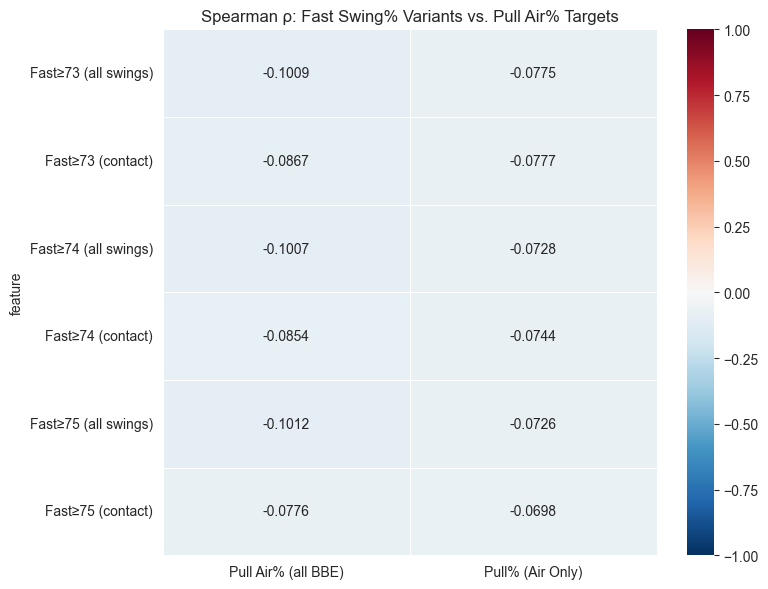

In [5]:
# Merge all fast swing% variants into pull_agg
merged = pull_agg.copy()
for t in FAST_THRESHOLDS:
    merged = merged.merge(
        fs_swings[t][["batter", f"fast_pct_all_{t}"]],
        on="batter", how="left"
    ).merge(
        fs_contact[t][["batter", f"fast_pct_contact_{t}"]],
        on="batter", how="left"
    )

# Correlation of each fast swing% variant vs pull air targets
targets = {
    "Pull Air% (all BBE)":   "pull_air_all",
    "Pull% (Air Only)":      "pull_given_air",
}

fast_cols = {}
for t in FAST_THRESHOLDS:
    fast_cols[f"Fast≥{t} (all swings)"] = f"fast_pct_all_{t}"
    fast_cols[f"Fast≥{t} (contact)"]    = f"fast_pct_contact_{t}"

print(f"{'Feature':<28}", end="")
for t_label in targets:
    print(f"  {t_label[:22]:>22}", end="")
print()
print("-" * (28 + 24 * len(targets)))

corr_rows = []
for f_label, f_col in fast_cols.items():
    row = {"feature": f_label}
    print(f"{f_label:<28}", end="")
    for t_label, t_col in targets.items():
        paired = merged[[f_col, t_col]].dropna()
        if len(paired) < 10:
            print(f"  {'n<10':>22}", end="")
            row[t_label] = np.nan
        else:
            rho, p = spearmanr(paired[f_col], paired[t_col])
            rho    = float(np.asarray(rho).flat[0])
            print(f"  {rho:>22.4f}", end="")
            row[t_label] = rho
    print()
    corr_rows.append(row)

corr_df = pd.DataFrame(corr_rows).set_index("feature")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_df, annot=True, fmt=".4f", cmap="RdBu_r", center=0,
            linewidths=0.5, linecolor="white", ax=ax, vmin=-1, vmax=1)
ax.set_title("Spearman ρ: Fast Swing% Variants vs. Pull Air% Targets")
plt.tight_layout()
plt.show()


## 6. OLS Regression — Scaled Predictors
All predictors standardised (mean=0, std=1) before fitting so coefficients
are comparable in magnitude. Reports β, std error, t-stat, and p-value.


In [6]:
def run_ols(df, predictor_cols, target_col, predictor_labels=None):
    """
    Standardise predictors, fit OLS, return summary dataframe.
    """
    sub = df[predictor_cols + [target_col]].dropna()
    if len(sub) < 20:
        print(f"  Skipping {target_col} — only {len(sub)} rows")
        return None

    scaler = StandardScaler()
    X_sc   = scaler.fit_transform(sub[predictor_cols])
    X_sm   = sm.add_constant(X_sc)
    y      = sub[target_col].values

    model  = sm.OLS(y, X_sm).fit()

    labels = predictor_labels or predictor_cols
    result = pd.DataFrame({
        "Feature":  ["Intercept"] + labels,
        "β":         model.params,
        "Std Err":   model.bse,
        "t":         model.tvalues,
        "p-value":   model.pvalues,
    }).set_index("Feature")

    print(f"\nTarget: {target_col}  |  R²={model.rsquared:.4f}  "
          f"adj-R²={model.rsquared_adj:.4f}  n={len(sub)}")
    print(result.round(4).to_string())
    return result, model.rsquared


# ── Choose best fast swing% variant based on correlation results
# (update BEST_FAST_COL after reviewing section 5)
BEST_FAST_COL   = "fast_pct_all_75"    # ← update if another threshold is better
BEST_FAST_LABEL = "Fast≥75 (all swings)"

predictors = {
    "Tilt":            "mean_tilt",
    "Att Angle":       "mean_aa",
    "Att Dir":         "mean_dir",
    "Depth":           "mean_depth",
    BEST_FAST_LABEL:   BEST_FAST_COL,
}

pred_cols   = list(predictors.values())
pred_labels = list(predictors.keys())

print("=" * 70)
for t_label, t_col in targets.items():
    print(f"\n{'='*70}")
    result = run_ols(merged, pred_cols, t_col, pred_labels)




Target: pull_air_all  |  R²=0.1022  adj-R²=0.0957  n=689
                           β  Std Err        t  p-value
Feature                                                
Intercept             0.2914   0.0017 170.9309   0.0000
Tilt                  0.0148   0.0018   8.4125   0.0000
Att Angle            -0.0021   0.0018  -1.1939   0.2329
Att Dir              -0.0004   0.0017  -0.2500   0.8026
Depth                 0.0017   0.0017   0.9996   0.3178
Fast≥75 (all swings) -0.0033   0.0017  -1.9433   0.0524


Target: pull_given_air  |  R²=0.2206  adj-R²=0.2149  n=689
                           β  Std Err        t  p-value
Feature                                                
Intercept             0.5288   0.0030 177.2541   0.0000
Tilt                  0.0186   0.0031   6.0129   0.0000
Att Angle            -0.0343   0.0031 -10.9938   0.0000
Att Dir               0.0056   0.0030   1.8772   0.0609
Depth                -0.0142   0.0031  -4.6414   0.0000
Fast≥75 (all swings) -0.0031   0.0030  -

In [7]:
# ── Run all three thresholds × both denominators for comparison ───────────────
print("\nR² comparison across Fast Swing% threshold and denominator:")
print(f"{'Fast col':<30}  {'Pull Air% R²':>14}  {'PullAirOnly R²':>16}")
print("-" * 65)

for t in FAST_THRESHOLDS:
    for denom, col_stem in [("all swings", "all"), ("contact", "contact")]:
        f_col = f"fast_pct_{col_stem}_{t}"
        preds = ["mean_tilt", "mean_aa", "mean_dir", "mean_depth", f_col]
        r2s   = []
        for t_col in ["pull_air_all", "pull_given_air"]:
            sub = merged[preds + [t_col]].dropna()
            if len(sub) < 20:
                r2s.append(np.nan)
                continue
            scaler = StandardScaler()
            X_sc   = scaler.fit_transform(sub[preds])
            X_sm   = sm.add_constant(X_sc)
            model  = sm.OLS(sub[t_col].values, X_sm).fit()
            r2s.append(model.rsquared)
        label = f"Fast≥{t} ({denom})"
        print(f"{label:<30}  {r2s[0]:>14.4f}  {r2s[1]:>16.4f}")



R² comparison across Fast Swing% threshold and denominator:
Fast col                          Pull Air% R²    PullAirOnly R²
-----------------------------------------------------------------
Fast≥73 (all swings)                    0.1033            0.2214
Fast≥73 (contact)                       0.1032            0.2224
Fast≥74 (all swings)                    0.1029            0.2211
Fast≥74 (contact)                       0.1021            0.2220
Fast≥75 (all swings)                    0.1022            0.2206
Fast≥75 (contact)                       0.1005            0.2209


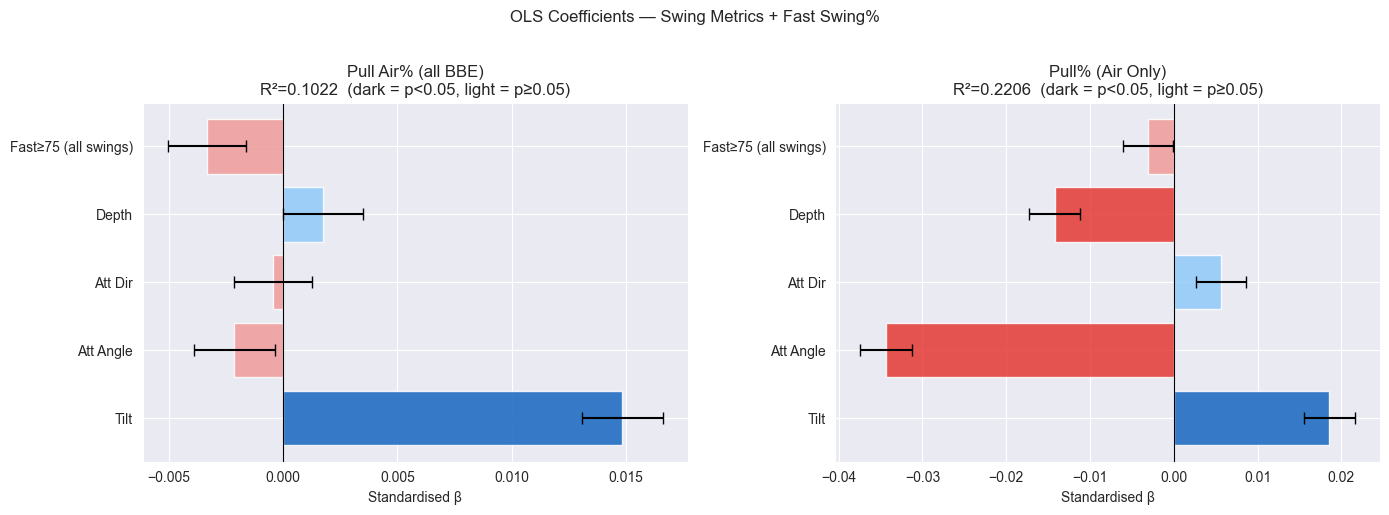

In [8]:
# ── Coefficient plot for best model ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (t_label, t_col) in zip(axes, targets.items()):
    sub = merged[pred_cols + [t_col]].dropna()
    scaler = StandardScaler()
    X_sc   = scaler.fit_transform(sub[pred_cols])
    X_sm   = sm.add_constant(X_sc)
    model  = sm.OLS(sub[t_col].values, X_sm).fit()

    coefs  = model.params[1:]     # drop intercept
    pvals  = model.pvalues[1:]
    errors = model.bse[1:]

    colors = []
    for p, c in zip(pvals, coefs):
        if p < 0.05:
            colors.append("#1565C0" if c > 0 else "#E53935")
        else:
            colors.append("#90CAF9" if c > 0 else "#EF9A9A")

    y_pos = range(len(pred_labels))
    ax.barh(list(y_pos), coefs, xerr=errors,
            color=colors, alpha=0.85, capsize=4)
    ax.set_yticks(list(y_pos))
    ax.set_yticklabels(pred_labels)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Standardised β")
    ax.set_title(f"{t_label}\nR²={model.rsquared:.4f}  "
                 f"(dark = p<0.05, light = p≥0.05)")

plt.suptitle("OLS Coefficients — Swing Metrics + Fast Swing%",
             y=1.02, fontsize=12)
plt.tight_layout()
plt.show()
